# CLAHE: small TrOCR validation experiment

This notebook tries CLAHE (a way of making light and dark areas clearer) on 10 IAM validation images. It compares the original images with CLAHE using the same pretrained TrOCR model and the same images. It only measures these 10 examples; a better score here is an early hint, not proof that CLAHE helps overall. The test split stays saved for the final evaluation.

CLAHE is written inside this notebook as a temporary experiment. It does not change the reusable preprocessing pipeline. Run the cells from top to bottom. The first run may download the dataset and model.


In [1]:
import sys
from pathlib import Path
import json

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.load_dataset.iam import load_iam_dataset, get_sample
from src.preprocessing import PreprocessingPipeline
from src.models.trocr import TrOCRRecognizer
from src.evaluation import compare_recognition

class TryCLAHE:
    """Temporary grayscale CLAHE step for this notebook only."""
    enabled = True
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size
    def __call__(self, image):
        gray = np.asarray(image.convert('L'))
        enhanced = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size).apply(gray)
        return Image.fromarray(enhanced)
    def to_config(self):
        return {'name': 'clahe_trial', 'enabled': self.enabled, 'clip_limit': self.clip_limit, 'tile_grid_size': list(self.tile_grid_size), 'input_output_mode': 'L'}


C:\Users\chirayu ubale\OneDrive\Desktop\Research Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SPLIT = 'validation'
SAMPLE_INDICES = tuple(range(10))  # Try a few; later run more validation examples.
CHECKPOINT = 'microsoft/trocr-base-handwritten'
MODEL_REVISION = 'main'
DEVICE = 'cpu'
GENERATION = {'max_new_tokens': 128, 'num_beams': 1, 'do_sample': False}
clahe = TryCLAHE(clip_limit=2.0, tile_grid_size=(8, 8))
pipelines = {
    'baseline': PreprocessingPipeline(),
    'clahe_trial': PreprocessingPipeline((clahe,)),
}
print(json.dumps({name: pipeline.to_config() for name, pipeline in pipelines.items()}, indent=2))


{
  "baseline": {
    "steps": []
  },
  "clahe_trial": {
    "steps": [
      {
        "name": "clahe_trial",
        "enabled": true,
        "clip_limit": 2.0,
        "tile_grid_size": [
          8,
          8
        ],
        "input_output_mode": "L"
      }
    ]
  }
}


In [3]:
assert SPLIT == 'validation', 'Use validation while trying settings.'
dataset = load_iam_dataset(split=SPLIT)
indices = SAMPLE_INDICES
assert indices and len(set(indices)) == len(indices)
assert all(0 <= i < len(dataset) for i in indices)
samples = [get_sample(dataset, i) for i in indices]
print('Validation split size:', len(dataset), '| selected examples:', len(samples))
for sample in samples[:3]:
    print(sample['id'], repr(sample['ground_truth']))


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Validation split size: 976 | selected examples: 10
sample_0 'It was a splendid interpretation of the'
sample_1 'sympathetic C O . Paul Daneman gave another'
sample_2 'part . The rest of the cast were well chosen ,'


sample_0 text: It was a splendid interpretation of the
sample_1 text: sympathetic C O . Paul Daneman gave another
sample_2 text: part . The rest of the cast were well chosen ,


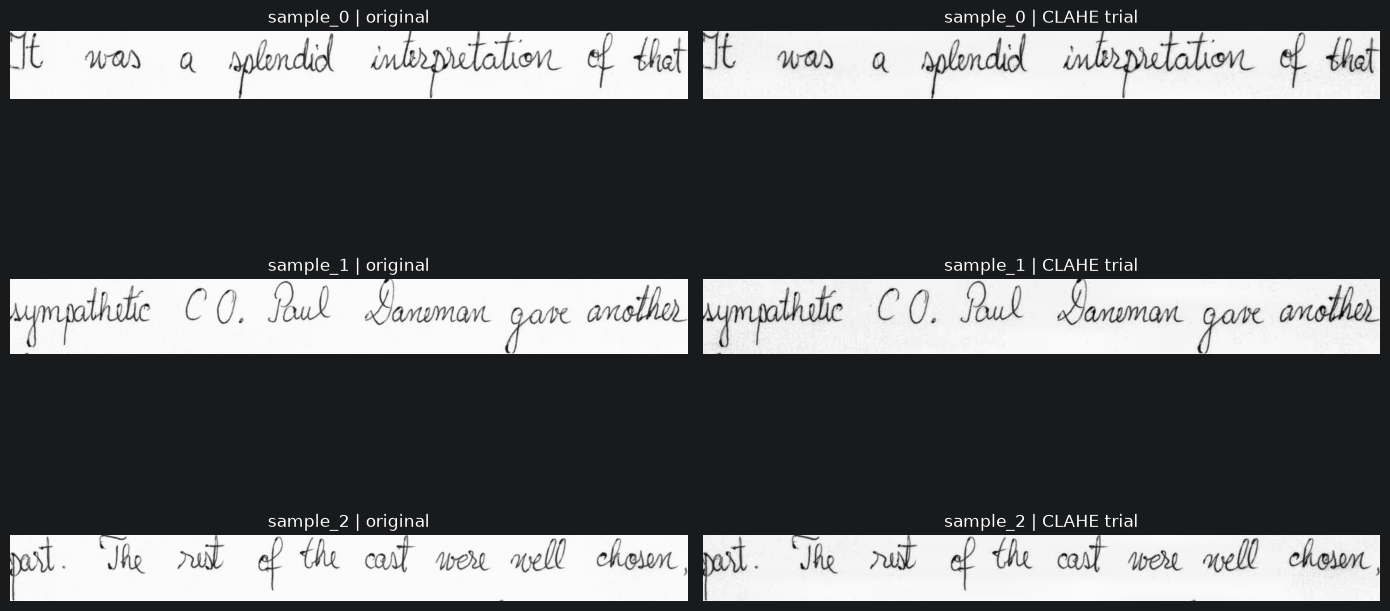

In [4]:
fig, axes = plt.subplots(min(3, len(samples)), 2, figsize=(14, 3 * min(3, len(samples))), squeeze=False)
for row, sample in enumerate(samples[:3]):
    axes[row, 0].imshow(sample['image'], cmap='gray')
    axes[row, 0].set_title(f"{sample['id']} | original")
    axes[row, 1].imshow(clahe(sample['image']), cmap='gray')
    axes[row, 1].set_title(f"{sample['id']} | CLAHE trial")
    for ax in axes[row]:
        ax.axis('off')
    print(sample['id'], 'text:', sample['ground_truth'])
fig.tight_layout()
plt.show()


In [5]:
# Load TrOCR once; both versions use this exact same model and settings.
model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION, device=DEVICE, generation_kwargs=GENERATION)
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index('configuration')
summary


Loading weights: 100%|██████████| 478/478 [00:01<00:00, 359.55it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline: 1/10
baseline: 2/10
baseline: 3/10
baseline: 4/10
baseline: 5/10
baseline: 6/10
baseline: 7/10
baseline: 8/10
baseline: 9/10
baseline: 10/10
clahe_trial: 1/10
clahe_trial: 2/10
clahe_trial: 3/10
clahe_trial: 4/10
clahe_trial: 5/10
clahe_trial: 6/10
clahe_trial: 7/10
clahe_trial: 8/10
clahe_trial: 9/10
clahe_trial: 10/10


,sample_count,cer,wer,inference_seconds
configuration,,,,
baseline,10,0.030691,0.121951,41.559288
clahe_trial,10,0.025575,0.109756,29.730076


In [6]:
# Negative change means CLAHE's error rate was lower on this small sample.
summary['cer_change_vs_baseline'] = summary['cer'] - summary.loc['baseline', 'cer']
summary['wer_change_vs_baseline'] = summary['wer'] - summary.loc['baseline', 'wer']
summary[['sample_count', 'cer', 'wer', 'cer_change_vs_baseline', 'wer_change_vs_baseline']]


,sample_count,cer,wer,cer_change_vs_baseline,wer_change_vs_baseline
configuration,,,,,
baseline,10,0.030691,0.121951,0.000000,0.000000
clahe_trial,10,0.025575,0.109756,-0.005115,-0.012195


## How to read this

CER and WER are error scores; smaller is better. A negative change means the CLAHE trial made fewer text mistakes in this sample. Look at the displayed images too: stronger contrast can also make handwriting strokes harsher or disappear. If these 10 examples look promising, try more fixed validation examples with the same settings. Only add CLAHE to the reusable preprocessing code after a fair validation comparison; save the test split for the final check.
